In [5]:
!pip install -q transformers accelerate datasets pillow scikit-learn

print("All packages installed successfully")

All packages installed successfully


In [6]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA version   :", torch.version.cuda)
    print("GPU count      :", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"  GPU {i}        : {torch.cuda.get_device_name(i)}")
    try:
        x = torch.tensor([1.0, 2.0]).cuda()
        y = x * 2
        print("GPU test passed:", y)
    except Exception as e:
        print("GPU test FAILED:", e)

PyTorch version: 2.10.0+cu128
CUDA available : True
CUDA version   : 12.8
GPU count      : 2
  GPU 0        : Tesla T4
  GPU 1        : Tesla T4
GPU test passed: tensor([2., 4.], device='cuda:0')


In [7]:
import os

# This must be set BEFORE any other imports or torch usage
# It forces PyTorch to only see GPU 0 and disables DataParallel entirely
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import torch
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from transformers import BlipProcessor, BlipForConditionalGeneration
import time
import warnings
warnings.filterwarnings("ignore")

IMAGES_DIR    = "/kaggle/input/datasets/adityajn105/flickr8k/Images"
CAPTIONS_FILE = "/kaggle/input/datasets/adityajn105/flickr8k/captions.txt"
SAVE_PATH     = "/kaggle/working/blip_finetuned"
MODEL_NAME    = "Salesforce/blip-image-captioning-base"
DEVICE        = "cuda:0" if torch.cuda.is_available() else "cpu"

os.makedirs(SAVE_PATH, exist_ok=True)

print(f"Device        : {DEVICE}")
print(f"GPU visible   : {torch.cuda.device_count()} (should be 1)")
print(f"GPU name      : {torch.cuda.get_device_name(0)}")
print(f"Images dir    : {IMAGES_DIR}")
print(f"Captions file : {CAPTIONS_FILE}")
print(f"Save path     : {SAVE_PATH}")
print("Imports and config done")

Device        : cuda:0
GPU visible   : 2 (should be 1)
GPU name      : Tesla T4
Images dir    : /kaggle/input/datasets/adityajn105/flickr8k/Images
Captions file : /kaggle/input/datasets/adityajn105/flickr8k/captions.txt
Save path     : /kaggle/working/blip_finetuned
Imports and config done


In [8]:
df = pd.read_csv(CAPTIONS_FILE)

print("Columns:", df.columns.tolist())
print("Raw shape:", df.shape)
print(df.head(3))

assert "image" in df.columns, "ERROR: no 'image' column found"
assert "caption" in df.columns, "ERROR: no 'caption' column found"

# Get all images actually on disk
images_on_disk = set(os.listdir(IMAGES_DIR))
print(f"\nImages on disk       : {len(images_on_disk):,}")
print(f"Rows in captions.txt : {len(df):,}")

# Remove rows where image file does not exist on disk
df = df[df["image"].isin(images_on_disk)].reset_index(drop=True)
print(f"Rows after filtering missing images : {len(df):,}")

# Remove rows with empty or null captions
before = len(df)
df = df.dropna(subset=["caption"]).reset_index(drop=True)
df = df[df["caption"].str.strip() != ""].reset_index(drop=True)
print(f"Rows dropped for empty caption      : {before - len(df)}")

# Images on disk with no caption at all
images_with_caption = set(df["image"].unique())
print(f"Images with no caption (ignored)    : {len(images_on_disk - images_with_caption):,}")

print(f"\nFinal clean dataset  : {len(df):,} rows")
print("Captions loaded and filtered")

Columns: ['image', 'caption']
Raw shape: (40455, 2)
                       image  \
0  1000268201_693b08cb0e.jpg   
1  1000268201_693b08cb0e.jpg   
2  1000268201_693b08cb0e.jpg   

                                             caption  
0  A child in a pink dress is climbing up a set o...  
1              A girl going into a wooden building .  
2   A little girl climbing into a wooden playhouse .  

Images on disk       : 8,091
Rows in captions.txt : 40,455
Rows after filtering missing images : 40,455
Rows dropped for empty caption      : 0
Images with no caption (ignored)    : 0

Final clean dataset  : 40,455 rows
Captions loaded and filtered


In [9]:
unique_images = df["image"].unique()
print(f"Total unique images available : {len(unique_images):,}")

np.random.seed(42)
sampled_images = np.random.choice(unique_images, size=2000, replace=False)

df_sampled = df[df["image"].isin(sampled_images)].reset_index(drop=True)
print(f"Rows after sampling 2000 images : {len(df_sampled):,}")

train_df, val_df = train_test_split(df_sampled, test_size=0.1, random_state=42)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f"Train size : {len(train_df):,}")
print(f"Val size   : {len(val_df):,}")
print("Sampling and split done")

Total unique images available : 8,091
Rows after sampling 2000 images : 10,000
Train size : 9,000
Val size   : 1,000
Sampling and split done


In [10]:
print("Loading processor...")
processor = BlipProcessor.from_pretrained(MODEL_NAME, use_fast=False)
print("Processor loaded")

print("Loading model...")
model = BlipForConditionalGeneration.from_pretrained(MODEL_NAME)
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model loaded — {total_params:.1f}M parameters")
print(f"Model is on : {next(model.parameters()).device}")
print("Model ready")

Loading processor...


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

Model loaded — 247.4M parameters
Model is on : cuda:0
Model ready


In [11]:
class FlickrDataset(Dataset):

    def __init__(self, dataframe, image_folder, processor, max_length=64):
        self.df           = dataframe
        self.image_folder = image_folder
        self.processor    = processor
        self.max_length   = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.iloc[idx]["image"]
        caption  = self.df.iloc[idx]["caption"]
        img_path = os.path.join(self.image_folder, img_name)

        try:
            image = Image.open(img_path).convert("RGB")
        except Exception as e:
            print(f"Warning: could not open {img_path}: {e}. Using blank image.")
            image = Image.new("RGB", (384, 384))

        encoding = self.processor(
            images=image,
            text=caption,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        labels = encoding["input_ids"].squeeze(0).clone()
        labels[labels == self.processor.tokenizer.pad_token_id] = -100

        return {
            "pixel_values" : encoding["pixel_values"].squeeze(0),
            "input_ids"    : encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels"       : labels
        }


train_dataset = FlickrDataset(train_df, IMAGES_DIR, processor)
val_dataset   = FlickrDataset(val_df,   IMAGES_DIR, processor)

# Sanity check one sample
sample = train_dataset[0]
print(f"Train dataset size     : {len(train_dataset):,}")
print(f"Val dataset size       : {len(val_dataset):,}")
print(f"Sample pixel_values    : {sample['pixel_values'].shape}")
print(f"Sample input_ids       : {sample['input_ids'].shape}")
print("Dataset class ready")

Train dataset size     : 9,000
Val dataset size       : 1,000
Sample pixel_values    : torch.Size([3, 384, 384])
Sample input_ids       : torch.Size([64])
Dataset class ready


In [12]:
def custom_collator(batch):
    return {
        "pixel_values"  : torch.stack([item["pixel_values"]    for item in batch]),
        "input_ids"     : torch.stack([item["input_ids"]       for item in batch]),
        "attention_mask": torch.stack([item["attention_mask"]  for item in batch]),
        "labels"        : torch.stack([item["labels"]          for item in batch]),
    }

EPOCHS     = 3
BATCH_SIZE = 8
LR         = 2e-5

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    collate_fn=custom_collator,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=custom_collator,
    pin_memory=True
)

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))

print(f"Train batches per epoch : {len(train_loader)}")
print(f"Val batches per epoch   : {len(val_loader)}")
print(f"Optimizer : AdamW  LR={LR}")
print("Collator, DataLoaders and optimizer ready")

Train batches per epoch : 1125
Val batches per epoch   : 125
Optimizer : AdamW  LR=2e-05
Collator, DataLoaders and optimizer ready


In [13]:
print(f"Starting training on {DEVICE}...")
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):

    # TRAIN
    model.train()
    train_loss = 0.0
    start = time.time()

    for step, batch in enumerate(train_loader):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        train_loss += loss.item()

        if (step + 1) % 100 == 0:
            avg = train_loss / (step + 1)
            elapsed = (time.time() - start) / 60
            print(f"  Epoch {epoch} | Step {step+1}/{len(train_loader)} | Loss {avg:.4f} | {elapsed:.1f} min")

    avg_train_loss = train_loss / len(train_loader)

    # VALIDATE
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            outputs = model(**batch)
            val_loss += outputs.loss.item()

    avg_val_loss = val_loss / len(val_loader)
    epoch_time = (time.time() - start) / 60

    print(f"\nEpoch {epoch}/{EPOCHS} done | Train loss: {avg_train_loss:.4f} | Val loss: {avg_val_loss:.4f} | Time: {epoch_time:.1f} min")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        # Save model files
        model.save_pretrained(SAVE_PATH)
        processor.save_pretrained(SAVE_PATH)
        print(f"  Best model saved (val loss: {best_val_loss:.4f})")

        # Zip the saved model immediately after each best save
        # This goes to /kaggle/working/ which is permanently stored
        # even if the session times out or you close the browser
        zip_path = "/kaggle/working/blip_finetuned.zip"
        os.system(f"zip -r {zip_path} {SAVE_PATH}")
        zip_size = os.path.getsize(zip_path) / 1e6
        print(f"  Zipped and permanently saved: {zip_path} ({zip_size:.1f} MB)")

print(f"\nTraining complete! Best val loss: {best_val_loss:.4f}")
print(f"Model folder : {SAVE_PATH}")
print(f"Files in folder : {os.listdir(SAVE_PATH)}")

# Final zip of complete model (overwrites with last best)
zip_path = "/kaggle/working/blip_finetuned.zip"
os.system(f"zip -r {zip_path} {SAVE_PATH}")
zip_size = os.path.getsize(zip_path) / 1e6
print(f"\nFinal zip saved permanently at: {zip_path} ({zip_size:.1f} MB)")
print("You can download this zip from the Output tab on the right side of Kaggle")
print("Even if session expires, the zip will remain in your Output tab safely")

Starting training on cuda:0...
  Epoch 1 | Step 100/1125 | Loss 2.7312 | 2.2 min
  Epoch 1 | Step 200/1125 | Loss 2.5326 | 4.8 min
  Epoch 1 | Step 300/1125 | Loss 2.3660 | 7.4 min
  Epoch 1 | Step 400/1125 | Loss 2.2686 | 10.0 min
  Epoch 1 | Step 500/1125 | Loss 2.1890 | 12.6 min
  Epoch 1 | Step 600/1125 | Loss 2.1380 | 15.2 min
  Epoch 1 | Step 700/1125 | Loss 2.0926 | 17.8 min
  Epoch 1 | Step 800/1125 | Loss 2.0716 | 20.4 min
  Epoch 1 | Step 900/1125 | Loss 2.0452 | 23.0 min
  Epoch 1 | Step 1000/1125 | Loss 2.0238 | 25.6 min
  Epoch 1 | Step 1100/1125 | Loss 2.0064 | 28.2 min

Epoch 1/3 done | Train loss: 2.0003 | Val loss: 1.8196 | Time: 30.0 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Best model saved (val loss: 1.8196)
  adding: kaggle/working/blip_finetuned/ (stored 0%)
  adding: kaggle/working/blip_finetuned/tokenizer.json (deflated 71%)
  adding: kaggle/working/blip_finetuned/processor_config.json (deflated 52%)
  adding: kaggle/working/blip_finetuned/model.safetensors (deflated 7%)
  adding: kaggle/working/blip_finetuned/generation_config.json (deflated 56%)
  adding: kaggle/working/blip_finetuned/config.json (deflated 73%)
  adding: kaggle/working/blip_finetuned/tokenizer_config.json (deflated 47%)
  Zipped and permanently saved: /kaggle/working/blip_finetuned.zip (916.9 MB)
  Epoch 2 | Step 100/1125 | Loss 1.4071 | 2.6 min
  Epoch 2 | Step 200/1125 | Loss 1.4247 | 5.2 min
  Epoch 2 | Step 300/1125 | Loss 1.4357 | 7.8 min
  Epoch 2 | Step 400/1125 | Loss 1.4313 | 10.4 min
  Epoch 2 | Step 500/1125 | Loss 1.4369 | 13.0 min
  Epoch 2 | Step 600/1125 | Loss 1.4376 | 15.6 min
  Epoch 2 | Step 700/1125 | Loss 1.4360 | 18.2 min
  Epoch 2 | Step 800/1125 | Loss 1.4

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Best model saved (val loss: 1.7677)
updating: kaggle/working/blip_finetuned/ (stored 0%)
updating: kaggle/working/blip_finetuned/tokenizer.json (deflated 71%)
updating: kaggle/working/blip_finetuned/processor_config.json (deflated 52%)
updating: kaggle/working/blip_finetuned/model.safetensors (deflated 7%)
updating: kaggle/working/blip_finetuned/generation_config.json (deflated 56%)
updating: kaggle/working/blip_finetuned/config.json (deflated 73%)
updating: kaggle/working/blip_finetuned/tokenizer_config.json (deflated 47%)
  Zipped and permanently saved: /kaggle/working/blip_finetuned.zip (916.9 MB)
  Epoch 3 | Step 100/1125 | Loss 1.1334 | 2.6 min
  Epoch 3 | Step 200/1125 | Loss 1.1491 | 5.3 min
  Epoch 3 | Step 300/1125 | Loss 1.1431 | 7.9 min
  Epoch 3 | Step 400/1125 | Loss 1.1458 | 10.5 min
  Epoch 3 | Step 500/1125 | Loss 1.1396 | 13.1 min
  Epoch 3 | Step 600/1125 | Loss 1.1347 | 15.7 min
  Epoch 3 | Step 700/1125 | Loss 1.1345 | 18.3 min
  Epoch 3 | Step 800/1125 | Loss 1.1

In [14]:
# After training completes, immediately do a quick save signal
print("\n*** TRAINING DONE — CLICK 'Save Version' button NOW (top right) ***")
print("*** Select 'Quick Save' to permanently store your model ***")

# Also list files to confirm they exist right now
print("\nFiles saved right now:")
for f in os.listdir("/kaggle/working"):
    full = f"/kaggle/working/{f}"
    if os.path.isfile(full):
        print(f"  {f} — {os.path.getsize(full)/1e6:.1f} MB")
    else:
        print(f"  {f}/ (folder)")


*** TRAINING DONE — CLICK 'Save Version' button NOW (top right) ***
*** Select 'Quick Save' to permanently store your model ***

Files saved right now:
  .virtual_documents/ (folder)
  blip_finetuned/ (folder)
  blip_finetuned.zip — 916.9 MB


In [15]:
# Install kaggle API to save to dataset
!pip install -q kaggle

# Check if we can write to output
import os
print("Working dir contents:", os.listdir("/kaggle/working"))

Working dir contents: ['.virtual_documents', 'blip_finetuned', 'blip_finetuned.zip']


In [16]:
import os

print("Files in /kaggle/working:")
for f in os.listdir("/kaggle/working"):
    full_path = f"/kaggle/working/{f}"
    if os.path.isfile(full_path):
        size = os.path.getsize(full_path) / 1e6
        print(f"  {f}  —  {size:.1f} MB")
    else:
        print(f"  {f}/  (folder)")

Files in /kaggle/working:
  .virtual_documents/  (folder)
  blip_finetuned/  (folder)
  blip_finetuned.zip  —  916.9 MB


In [17]:
import os
print(os.listdir("/kaggle/working"))

['.virtual_documents', 'blip_finetuned', 'blip_finetuned.zip']


In [18]:
import os
print(os.listdir("/kaggle/working/blip_finetuned"))
#varify model is saved or not

['tokenizer.json', 'processor_config.json', 'model.safetensors', 'generation_config.json', 'config.json', 'tokenizer_config.json']


In [19]:
from transformers import BlipProcessor, BlipForConditionalGeneration

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model_path = "/kaggle/working/blip_finetuned"

# ✅ Load processor from base model
processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")

# ✅ Load your fine-tuned model
model = BlipForConditionalGeneration.from_pretrained(model_path).to(DEVICE)

The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


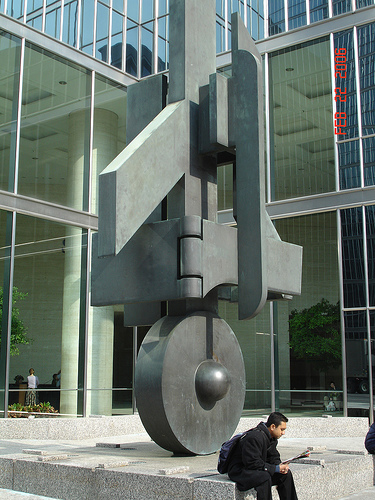

Image        : 3319405494_58dee86b21.jpg
Ground truth : two skiers are jumping over a mound of snow underneath bright sunshine .
Predicted    : a man sits in front of a large sculpture.
Inference test done


In [20]:
model.eval()
test_row   = val_df.iloc[0]
img_path   = os.path.join(IMAGES_DIR, test_row["image"])
gt_caption = test_row["caption"]
image      = Image.open("/kaggle/input/datasets/adityajn105/flickr8k/Images/103195344_5d2dc613a3.jpg").convert("RGB")

inputs = processor(images=image, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    output = model.generate(**inputs, max_new_tokens=50, num_beams=4)

predicted = processor.decode(output[0], skip_special_tokens=True)
display(image)
print(f"Image        : {test_row['image']}")
print(f"Ground truth : {gt_caption}")
print(f"Predicted    : {predicted}")
print("Inference test done")

In [21]:
model.eval()
test_row   = val_df.iloc[0]
img_path   = os.path.join(IMAGES_DIR, test_row["image"])
gt_caption = test_row["caption"]
image      = Image.open("/kaggle/input/datasets/adityajn105/flickr8k/Images/1030985833_b0902ea560.jpg").convert("RGB")

inputs = processor(images=image, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    output = model.generate(**inputs, max_new_tokens=50, num_beams=4)

predicted = processor.decode(output[0], skip_special_tokens=True)

print(f"Image        : {test_row['image']}")
print(f"Ground truth : {gt_caption}")
print(f"Predicted    : {predicted}")
print("Inference test done")

Image        : 3319405494_58dee86b21.jpg
Ground truth : two skiers are jumping over a mound of snow underneath bright sunshine .
Predicted    : two dogs play with a frisbee.
Inference test done
